# Aula 7.4 — Desafio final: investigando o Boosting

Dataset **Breast Cancer Wisconsin** (`load_breast_cancer`): 569 tumores de mama, 30 medidas das células. Aqui a classe **1 = maligno**, para que precisão e recall falem do caso que importa.

Comparamos **XGBoost, LightGBM e CatBoost** com o mesmo protocolo do exercício guiado: mesmos conjuntos de treino, validação e teste, early stopping pela AUC na **validação**, limiar comum de 0,5 e as mesmas métricas. O teste só é usado no fim.

| Etapa | O que faz |
|---|---|
| 01–03 | carregar, explorar e dividir em treino / validação / teste |
| 04–07 | treinar XGBoost, LightGBM e CatBoost com early stopping na validação |
| 08–10 | métricas, matrizes de confusão e tempo |
| 11–12 | comparar e interpretar (curvas de validação e importâncias) |
| 13 | ajustar dois hiperparâmetros por biblioteca |
| 14 | conclusão técnica |

## 01 · Carregar o dataset e registrar as versões

In [ ]:
import time
import warnings
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from catboost import CatBoostClassifier

# o LightGBM 4.7 avisa que eval_set vai mudar de nome; mantemos eval_set porque funciona em todas as versões
warnings.filterwarnings("ignore", message=".*eval_set.*")

for pacote in ["numpy", "pandas", "scikit-learn", "xgboost", "lightgbm", "catboost"]:
    print(f"{pacote}: {importlib.metadata.version(pacote)}")

dados = load_breast_cancer()
X = pd.DataFrame(dados.data, columns=dados.feature_names)
y = 1 - dados.target        # no original 0 = maligno; aqui invertemos: 1 = maligno
print()
print("X:", X.shape, "| malignos:", y.sum(), "| benignos:", (y == 0).sum())

numpy: 2.5.3
pandas: 3.0.5
scikit-learn: 1.9.1
xgboost: 3.4.1
lightgbm: 4.7.0
catboost: 1.2.10

X: (569, 30) | malignos: 212 | benignos: 357


## 02 · Explorar os dados

Valores ausentes: 0
Proporção de malignos: 0.373

                      count     mean      std      min      25%     50%  \
mean radius           569.0   14.127    3.524    6.981   11.700   13.37   
mean texture          569.0   19.290    4.301    9.710   16.170   18.84   
mean area             569.0  654.889  351.914  143.500  420.300  551.10   
worst concave points  569.0    0.115    0.066    0.000    0.065    0.10   

                          75%       max  
mean radius            15.780    28.110  
mean texture           21.800    39.280  
mean area             782.700  2501.000  
worst concave points    0.161     0.291  

Pares de variáveis com correlação > 0.9: 21


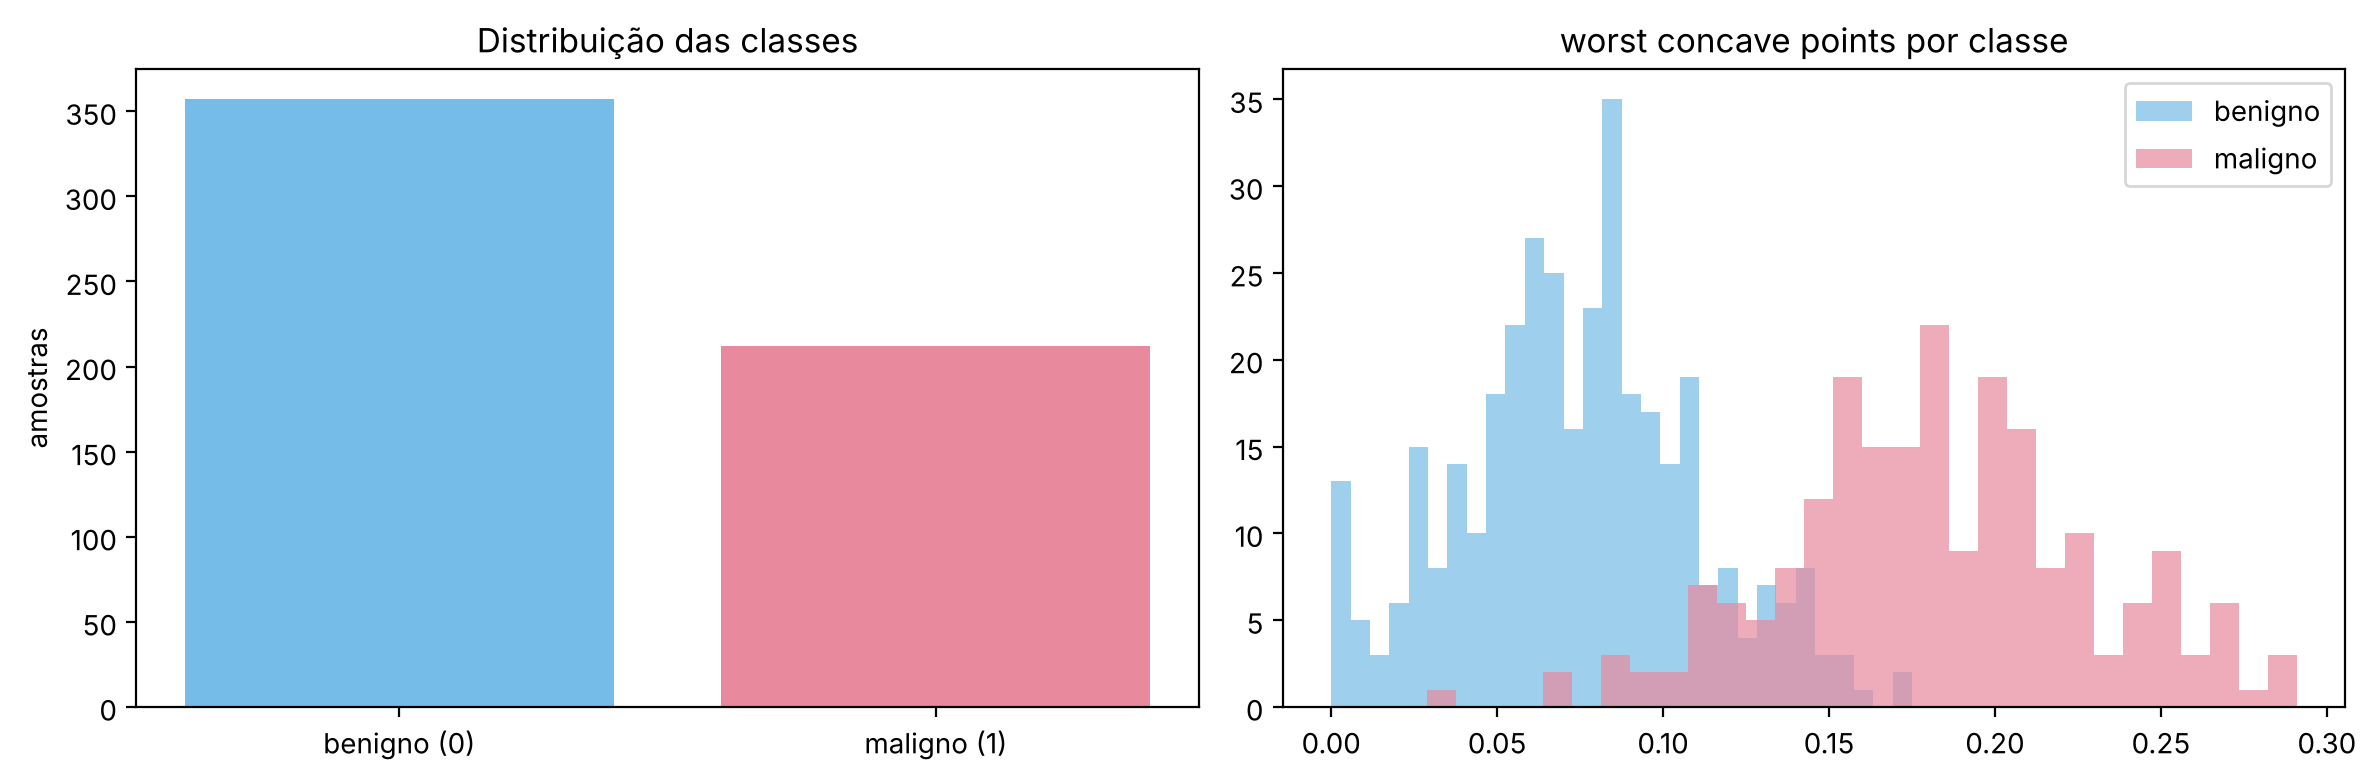

In [2]:
print("Valores ausentes:", X.isna().sum().sum())
print("Proporção de malignos: %.3f" % y.mean())
print()
print(X[["mean radius", "mean texture", "mean area", "worst concave points"]].describe().round(3).T)

corr = X.corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print()
print("Pares de variáveis com correlação > 0.9:", (pares > 0.9).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["benigno (0)", "maligno (1)"], np.bincount(y), color=["#75BCE8", "#E8899E"])
axes[0].set_title("Distribuição das classes"); axes[0].set_ylabel("amostras")
for classe, cor, nome in [(0, "#75BCE8", "benigno"), (1, "#E8899E", "maligno")]:
    axes[1].hist(X.loc[y == classe, "worst concave points"], bins=30, alpha=0.7, color=cor, label=nome)
axes[1].set_title("worst concave points por classe"); axes[1].legend()
plt.tight_layout(); plt.show()

## 03 · Dividir em treino, validação e teste (60 / 20 / 20, estratificado)

- **Treino:** as árvores aprendem aqui.
- **Validação:** o early stopping e a escolha de hiperparâmetros olham **só** para ela.
- **Teste:** usado uma única vez, no final. **Nunca** entra no `eval_set`.

In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print("Treino:   ", X_train.shape, "malignos:", y_train.sum())
print("Validação:", X_val.shape, "malignos:", y_val.sum())
print("Teste:    ", X_test.shape, "malignos:", y_test.sum())

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

Treino:    (341, 30) malignos: 127
Validação: (114, 30) malignos: 43
Teste:     (114, 30) malignos: 42


## 04 a 07 · Treinar XGBoost, LightGBM e CatBoost com early stopping na validação

Mesma ideia de configuração do exercício guiado: até 800 árvores, `learning_rate = 0.05`, árvores rasas e parada após **40 rodadas sem melhora da AUC na validação**. Junto vão o baseline (`DummyClassifier`) e, como referência da aula passada, uma Random Forest de 500 árvores.

In [4]:
def treinar_xgb(max_depth=4, learning_rate=0.05):
    m = XGBClassifier(n_estimators=800, max_depth=max_depth, learning_rate=learning_rate,
                      subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                      objective="binary:logistic", eval_metric="auc",
                      early_stopping_rounds=40, tree_method="hist",
                      random_state=42, n_jobs=-1)
    t0 = time.perf_counter()
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    return m, time.perf_counter() - t0, m.best_iteration + 1


def treinar_lgbm(num_leaves=15, min_child_samples=20):
    m = LGBMClassifier(n_estimators=800, learning_rate=0.05, max_depth=4, num_leaves=num_leaves,
                       min_child_samples=min_child_samples,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                       objective="binary", random_state=42, n_jobs=-1, verbosity=-1)
    t0 = time.perf_counter()
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="auc",
          callbacks=[early_stopping(40, verbose=False), log_evaluation(0)])
    return m, time.perf_counter() - t0, m.best_iteration_


def treinar_cat(depth=4, l2_leaf_reg=3.0):
    m = CatBoostClassifier(iterations=800, depth=depth, learning_rate=0.05, l2_leaf_reg=l2_leaf_reg,
                           loss_function="Logloss", eval_metric="AUC", random_seed=42,
                           verbose=False, allow_writing_files=False, thread_count=-1)
    t0 = time.perf_counter()
    m.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=40, verbose=False)
    return m, time.perf_counter() - t0, m.tree_count_


baseline = DummyClassifier(strategy="prior")
t0 = time.perf_counter(); baseline.fit(X_train, y_train); tempo_base = time.perf_counter() - t0

floresta = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
t0 = time.perf_counter(); floresta.fit(X_train, y_train); tempo_rf = time.perf_counter() - t0

modelo_xgb, tempo_xgb, arv_xgb = treinar_xgb()
modelo_lgbm, tempo_lgbm, arv_lgbm = treinar_lgbm()
modelo_cat, tempo_cat, arv_cat = treinar_cat()

print(f"XGBoost:  {arv_xgb:4d} árvores usadas (de 800) | {tempo_xgb:.3f} s")
print(f"LightGBM: {arv_lgbm:4d} árvores usadas (de 800) | {tempo_lgbm:.3f} s")
print(f"CatBoost: {arv_cat:4d} árvores usadas (de 800) | {tempo_cat:.3f} s")
print(f"Random Forest (referência): 500 árvores | {tempo_rf:.3f} s")

XGBoost:   148 árvores usadas (de 800) | 0.120 s
LightGBM:  111 árvores usadas (de 800) | 0.028 s
CatBoost:  157 árvores usadas (de 800) | 0.262 s
Random Forest (referência): 500 árvores | 0.620 s


**Configurações utilizadas**

| Biblioteca | Parâmetros |
|---|---|
| XGBoost | `max_depth=4`, `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8`, `reg_lambda=1`, `tree_method="hist"` |
| LightGBM | `num_leaves=15` (≤ 2⁴), `max_depth=4`, `min_child_samples=20`, `subsample=0.8` + `subsample_freq=1`, `colsample_bytree=0.8`, `reg_lambda=1` |
| CatBoost | `depth=4` (árvores simétricas, 16 folhas), `l2_leaf_reg=3` |
| Todas | até 800 árvores, early stopping de 40 rodadas pela AUC na validação, `random_state=42` |

## 08 · Mesmas métricas, mesmo limiar (0,5), no teste

In [5]:
LIMIAR = 0.5

def metricas(nome, modelo, tempo, arvores):
    proba = modelo.predict_proba(X_test)[:, list(modelo.classes_).index(1)]
    pred = (proba >= LIMIAR).astype(int)
    return {"Modelo": nome,
            "Acurácia": accuracy_score(y_test, pred),
            "Precisão": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, proba),
            "Log Loss": log_loss(y_test, proba, labels=[0, 1]),
            "Árvores": arvores,
            "Tempo (s)": tempo}

modelos = {"XGBoost": modelo_xgb, "LightGBM": modelo_lgbm, "CatBoost": modelo_cat}
tabela = pd.DataFrame([
    metricas("Baseline", baseline, tempo_base, 0),
    metricas("XGBoost", modelo_xgb, tempo_xgb, arv_xgb),
    metricas("LightGBM", modelo_lgbm, tempo_lgbm, arv_lgbm),
    metricas("CatBoost", modelo_cat, tempo_cat, arv_cat),
    metricas("Random Forest (ref.)", floresta, tempo_rf, 500),
]).set_index("Modelo")
print(tabela.round(4).to_string())
print()
print(f"No teste, 1 amostra = 1/{len(y_test)} = {100/len(y_test):.2f} p.p. de acurácia")

                      Acurácia  Precisão  Recall      F1  ROC AUC  Log Loss  Árvores  Tempo (s)
Modelo                                                                                         
Baseline                0.6316    0.0000  0.0000  0.0000   0.5000    0.6581        0     0.0127
XGBoost                 0.9737    1.0000  0.9286  0.9630   0.9947    0.0803      148     0.1198
LightGBM                0.9737    1.0000  0.9286  0.9630   0.9954    0.0847      111     0.0284
CatBoost                0.9737    1.0000  0.9286  0.9630   0.9950    0.0860      157     0.2616
Random Forest (ref.)    0.9561    0.9744  0.9048  0.9383   0.9957    0.1129      500     0.6202

No teste, 1 amostra = 1/114 = 0.88 p.p. de acurácia


## 09 · Matrizes de confusão (linhas = real, colunas = previsto)

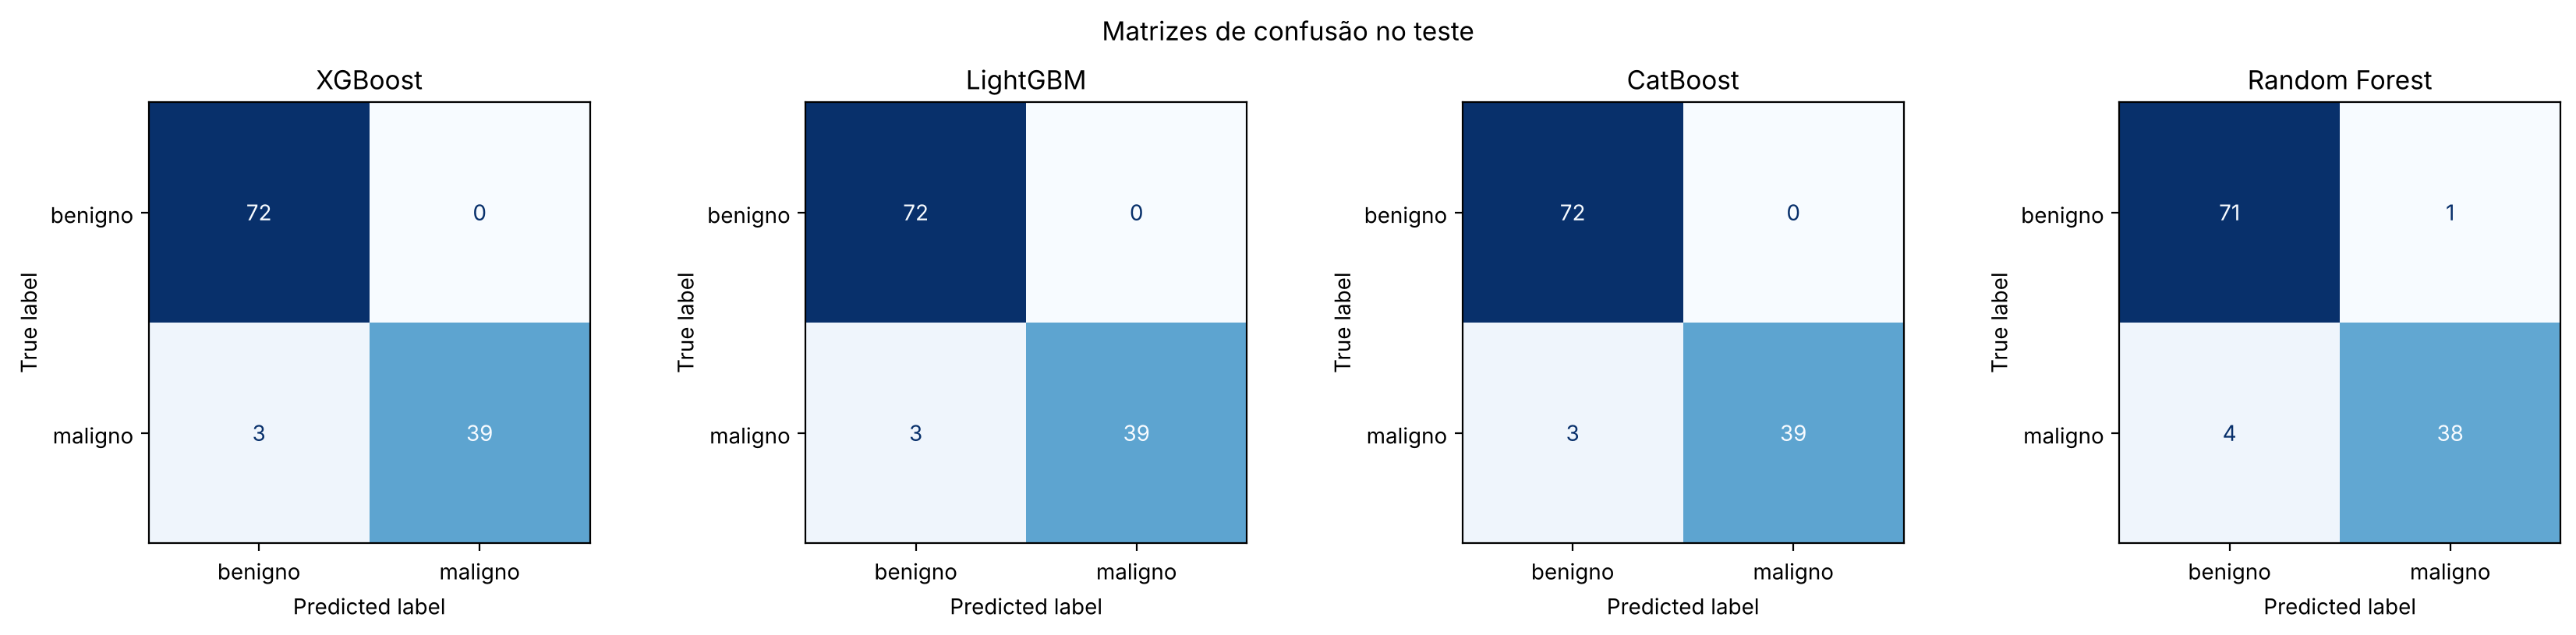

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (nome, m) in zip(axes, list(modelos.items()) + [("Random Forest", floresta)]):
    pred = (m.predict_proba(X_test)[:, 1] >= LIMIAR).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=["benigno", "maligno"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nome)
plt.suptitle("Matrizes de confusão no teste"); plt.tight_layout(); plt.show()

## 10 · Tempo de treinamento

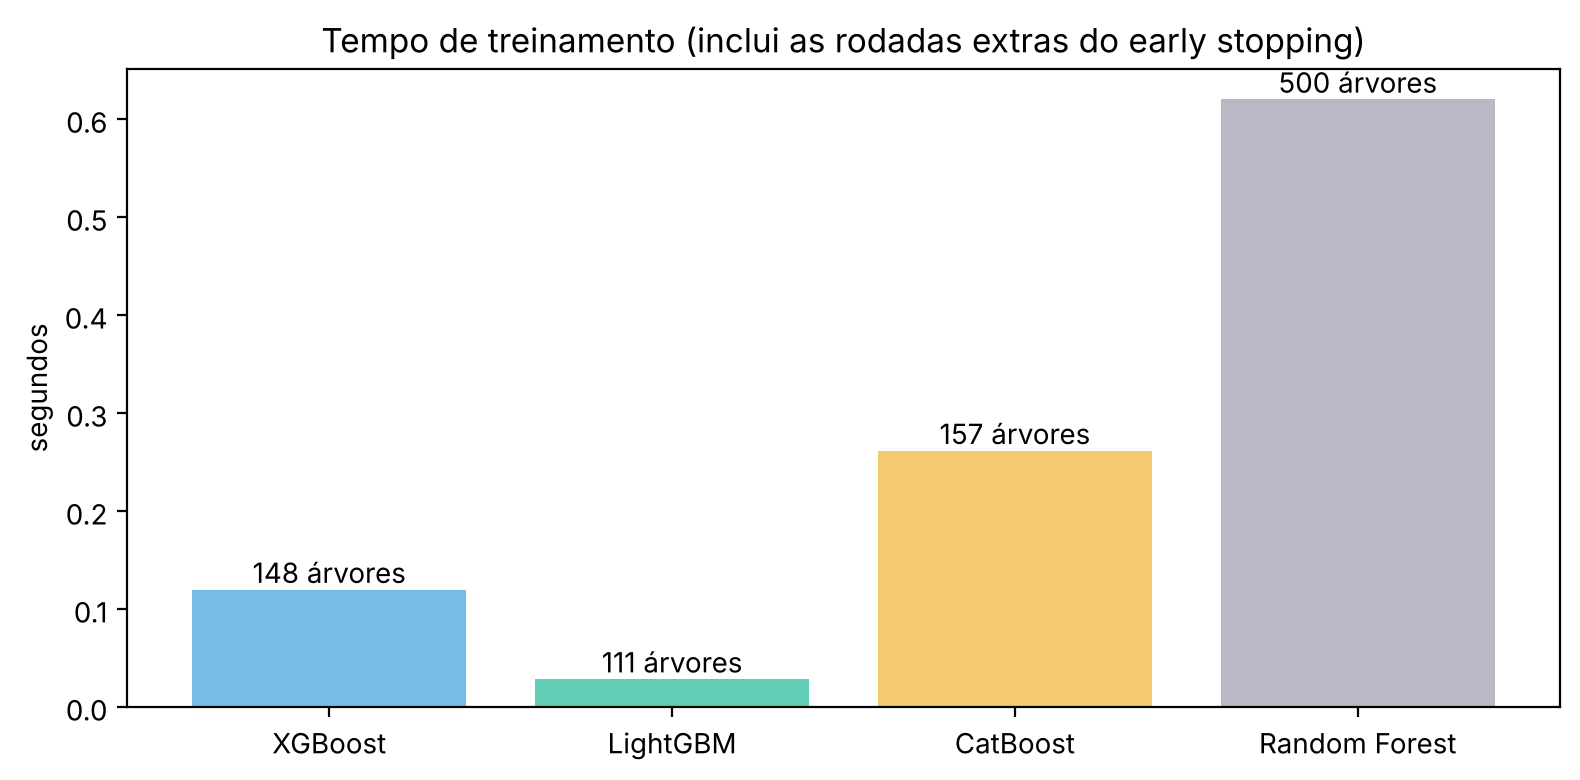

In [7]:
nomes = ["XGBoost", "LightGBM", "CatBoost", "Random Forest"]
tempos = [tempo_xgb, tempo_lgbm, tempo_cat, tempo_rf]
arvores = [arv_xgb, arv_lgbm, arv_cat, 500]

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(nomes, tempos, color=["#75BCE8", "#62CDB5", "#F4CA70", "#B9B9C6"])
for b, n in zip(barras, arvores):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n} árvores", ha="center", va="bottom")
ax.set_ylabel("segundos"); ax.set_title("Tempo de treinamento (inclui as rodadas extras do early stopping)")
plt.tight_layout(); plt.show()

## 11 · Comparar: curvas de validação e diferença treino × validação

As curvas mostram a AUC na validação a cada árvore. A linha tracejada marca onde o early stopping guardou o modelo.

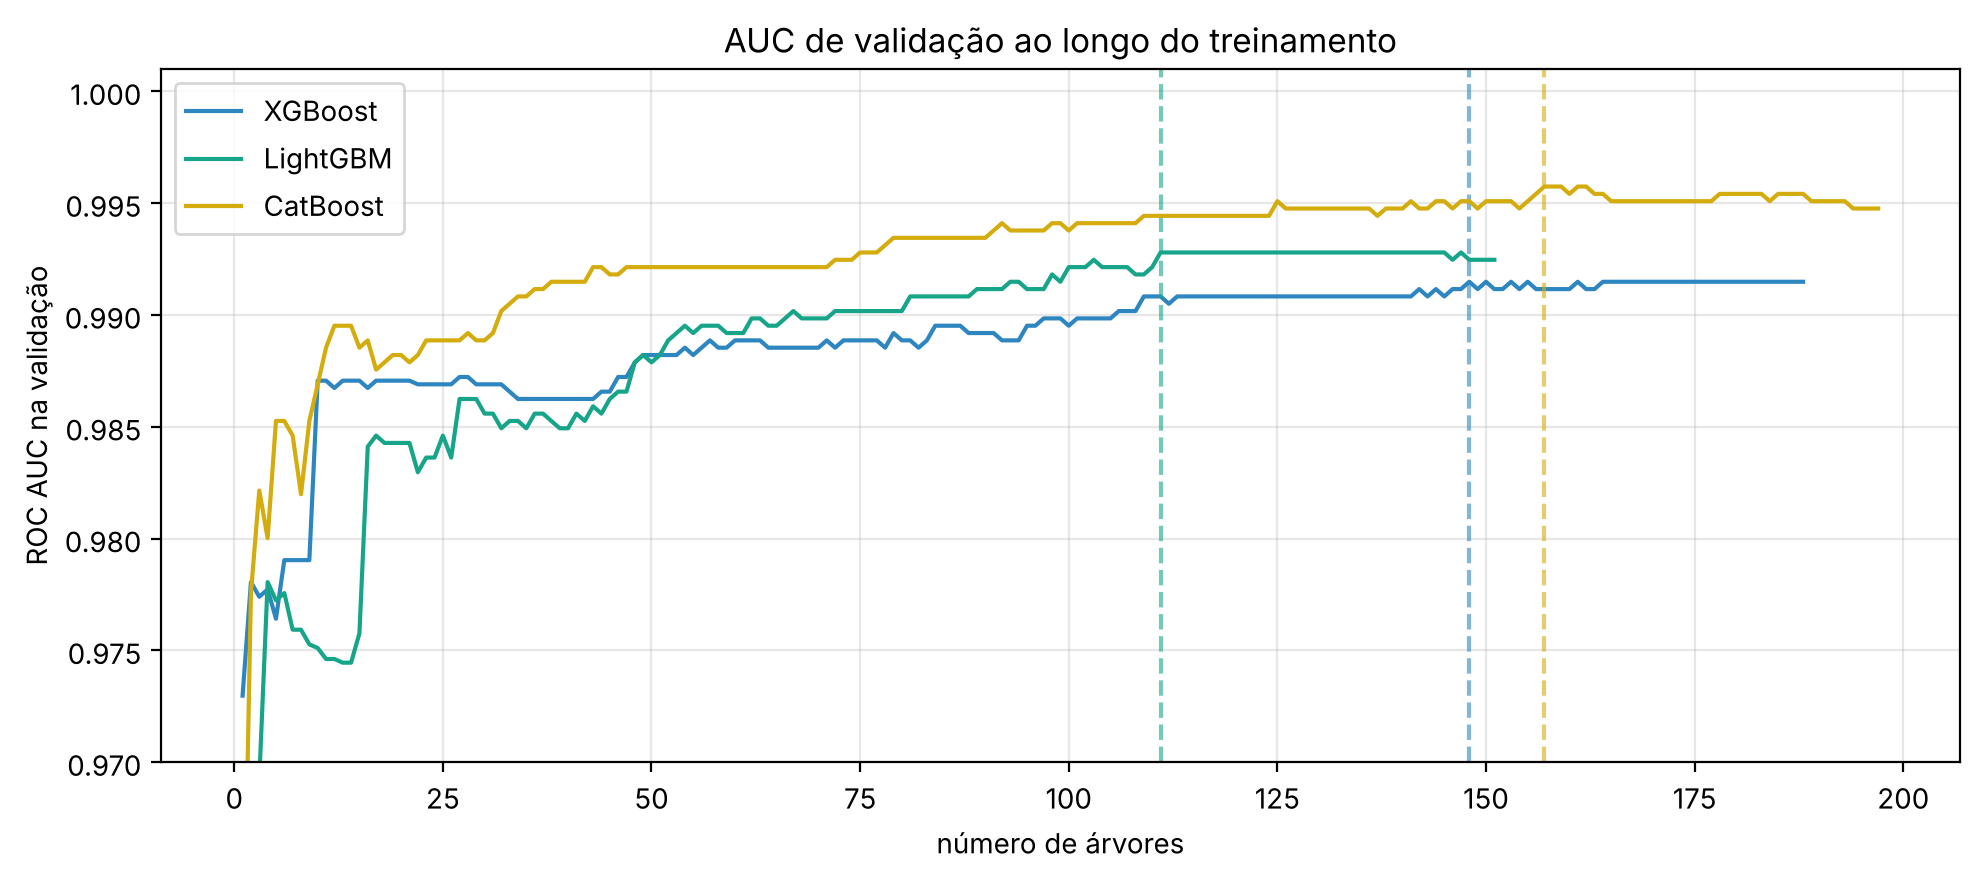

          AUC treino  AUC validação     Gap
Modelo                                     
XGBoost       1.0000         0.9915  0.0085
LightGBM      0.9999         0.9928  0.0071
CatBoost      1.0000         0.9957  0.0043


In [8]:
curvas = {"XGBoost": modelo_xgb.evals_result()["validation_0"]["auc"],
          "LightGBM": modelo_lgbm.evals_result_["valid_0"]["auc"],
          "CatBoost": modelo_cat.get_evals_result()["validation"]["AUC"]}
melhor = {"XGBoost": arv_xgb, "LightGBM": arv_lgbm, "CatBoost": arv_cat}
cores = {"XGBoost": "#2E86C1", "LightGBM": "#17A589", "CatBoost": "#D4AC0D"}

fig, ax = plt.subplots(figsize=(10, 4.5))
for nome, curva in curvas.items():
    ax.plot(range(1, len(curva) + 1), curva, color=cores[nome], label=nome)
    ax.axvline(melhor[nome], color=cores[nome], linestyle="--", alpha=0.6)
ax.set_xlabel("número de árvores"); ax.set_ylabel("ROC AUC na validação")
ax.set_ylim(0.97, 1.001); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("AUC de validação ao longo do treinamento")
plt.tight_layout(); plt.show()

linhas = []
for nome, m in modelos.items():
    auc_tr = roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])
    auc_va = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    linhas.append({"Modelo": nome, "AUC treino": auc_tr, "AUC validação": auc_va, "Gap": auc_tr - auc_va})
print(pd.DataFrame(linhas).set_index("Modelo").round(4).to_string())

## 12 · Interpretar: importância por permutação (AUC na validação)

As importâncias nativas (gain, split...) têm definições diferentes em cada biblioteca. Por isso usamos a **mesma** medida para as três: quanto a AUC cai quando uma coluna é embaralhada.

                      XGBoost  LightGBM  CatBoost   média
worst texture          0.0086    0.0095    0.0065  0.0082
area error             0.0052    0.0050    0.0017  0.0040
worst radius           0.0055    0.0030    0.0027  0.0037
worst concave points   0.0041    0.0054    0.0013  0.0036
worst perimeter        0.0032    0.0038    0.0014  0.0028
worst concavity        0.0032    0.0033    0.0018  0.0028
worst area             0.0027    0.0033    0.0022  0.0027
mean concave points    0.0018    0.0035    0.0015  0.0023

Concordância entre os rankings (Spearman):
          XGBoost  LightGBM  CatBoost
XGBoost     1.000     0.853     0.806
LightGBM    0.853     1.000     0.812
CatBoost    0.806     0.812     1.000


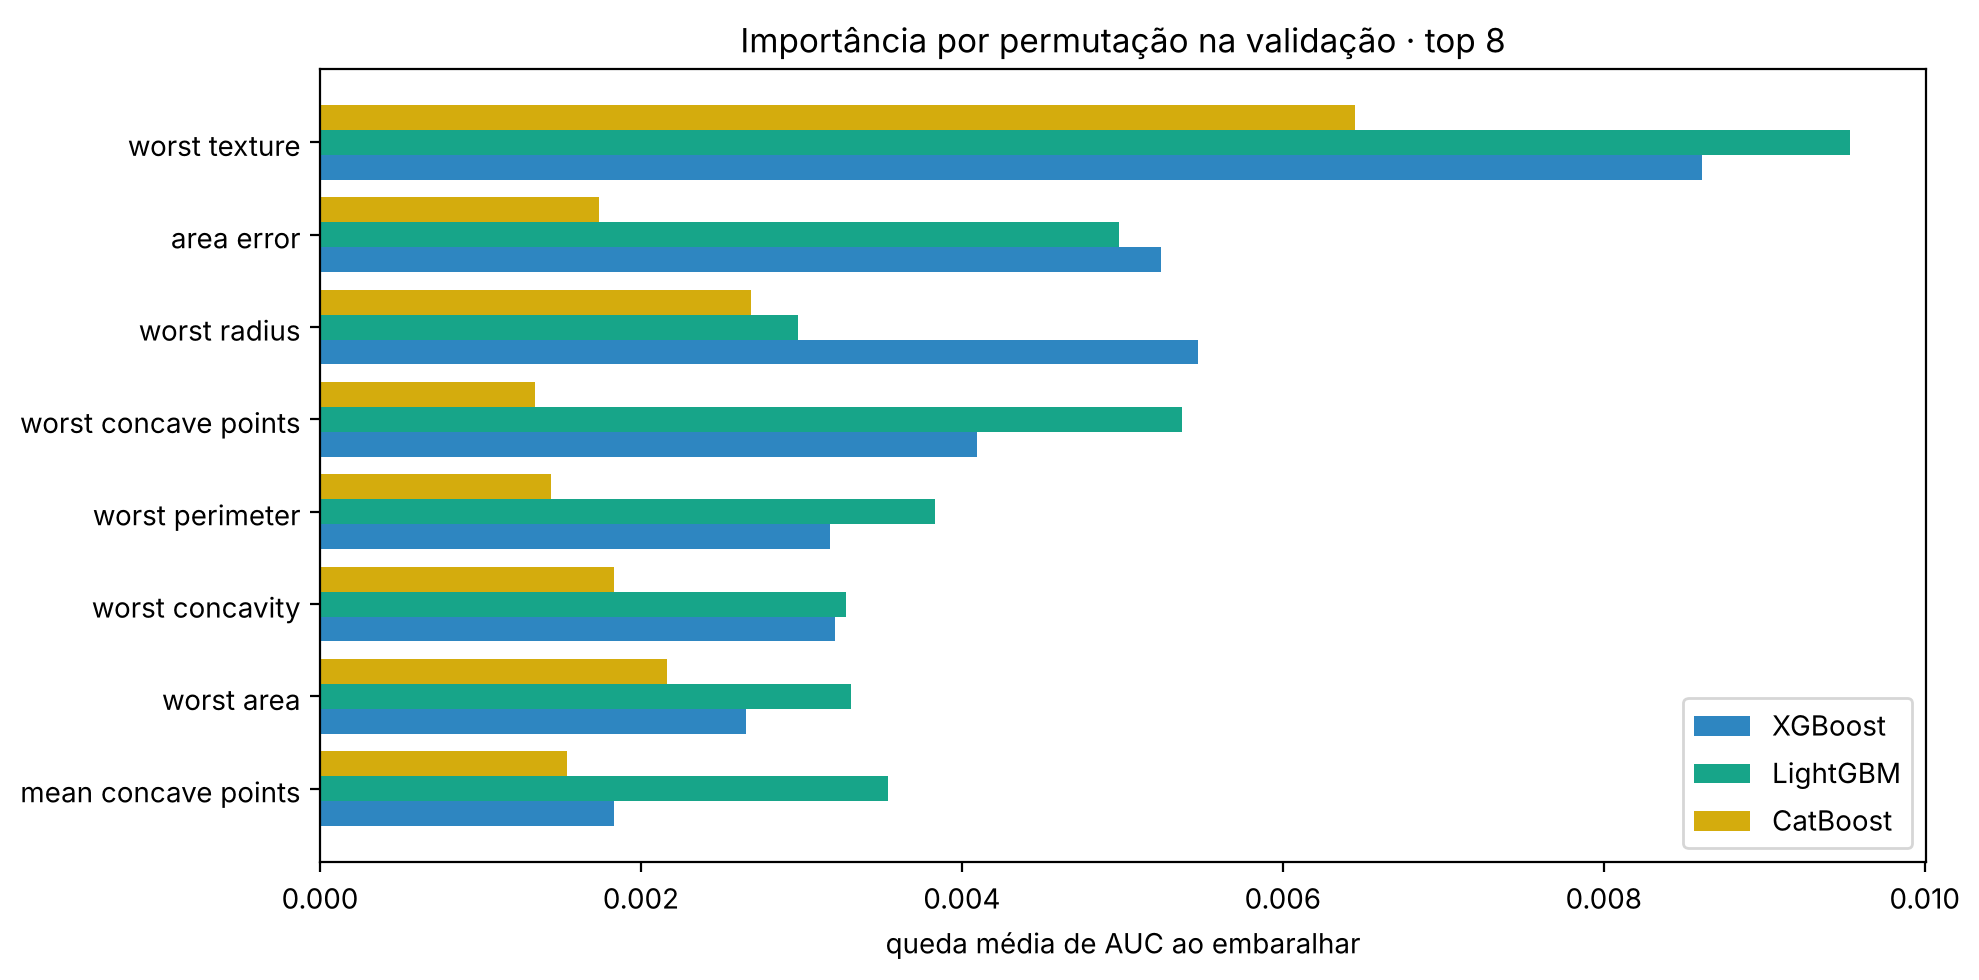

In [9]:
def auc_scorer(modelo, X_, y_):
    return roc_auc_score(y_, modelo.predict_proba(X_)[:, 1])

importancias = {}
for nome, m in modelos.items():
    r = permutation_importance(m, X_val, y_val, scoring=auc_scorer, n_repeats=10, random_state=42)
    importancias[nome] = r.importances_mean
imp = pd.DataFrame(importancias, index=X.columns)
imp["média"] = imp.mean(axis=1)
imp = imp.sort_values("média", ascending=False)
print(imp.head(8).round(4).to_string())
print()
print("Concordância entre os rankings (Spearman):")
print(imp[list(modelos)].corr(method="spearman").round(3).to_string())

top = imp.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(top))
for i, nome in enumerate(modelos):
    ax.barh(y_pos + (i - 1) * 0.27, top[nome], height=0.27, color=cores[nome], label=nome)
ax.set_yticks(y_pos); ax.set_yticklabels(top.index)
ax.set_xlabel("queda média de AUC ao embaralhar"); ax.legend()
ax.set_title("Importância por permutação na validação · top 8")
plt.tight_layout(); plt.show()

## 13 · Dois hiperparâmetros por biblioteca

Uma grade 3 × 3 para cada uma, **escolhida pela AUC na validação**. O teste continua guardado até a última célula.

| Biblioteca | Hiperparâmetro 1 | Hiperparâmetro 2 |
|---|---|---|
| XGBoost | `max_depth` (2, 4, 6) | `learning_rate` (0.03, 0.1, 0.3) |
| LightGBM | `num_leaves` (4, 8, 15), sempre ≤ 2⁴ porque `max_depth=4` | `min_child_samples` (5, 20, 40) |
| CatBoost | `depth` (3, 4, 6) | `l2_leaf_reg` (1, 3, 10) |

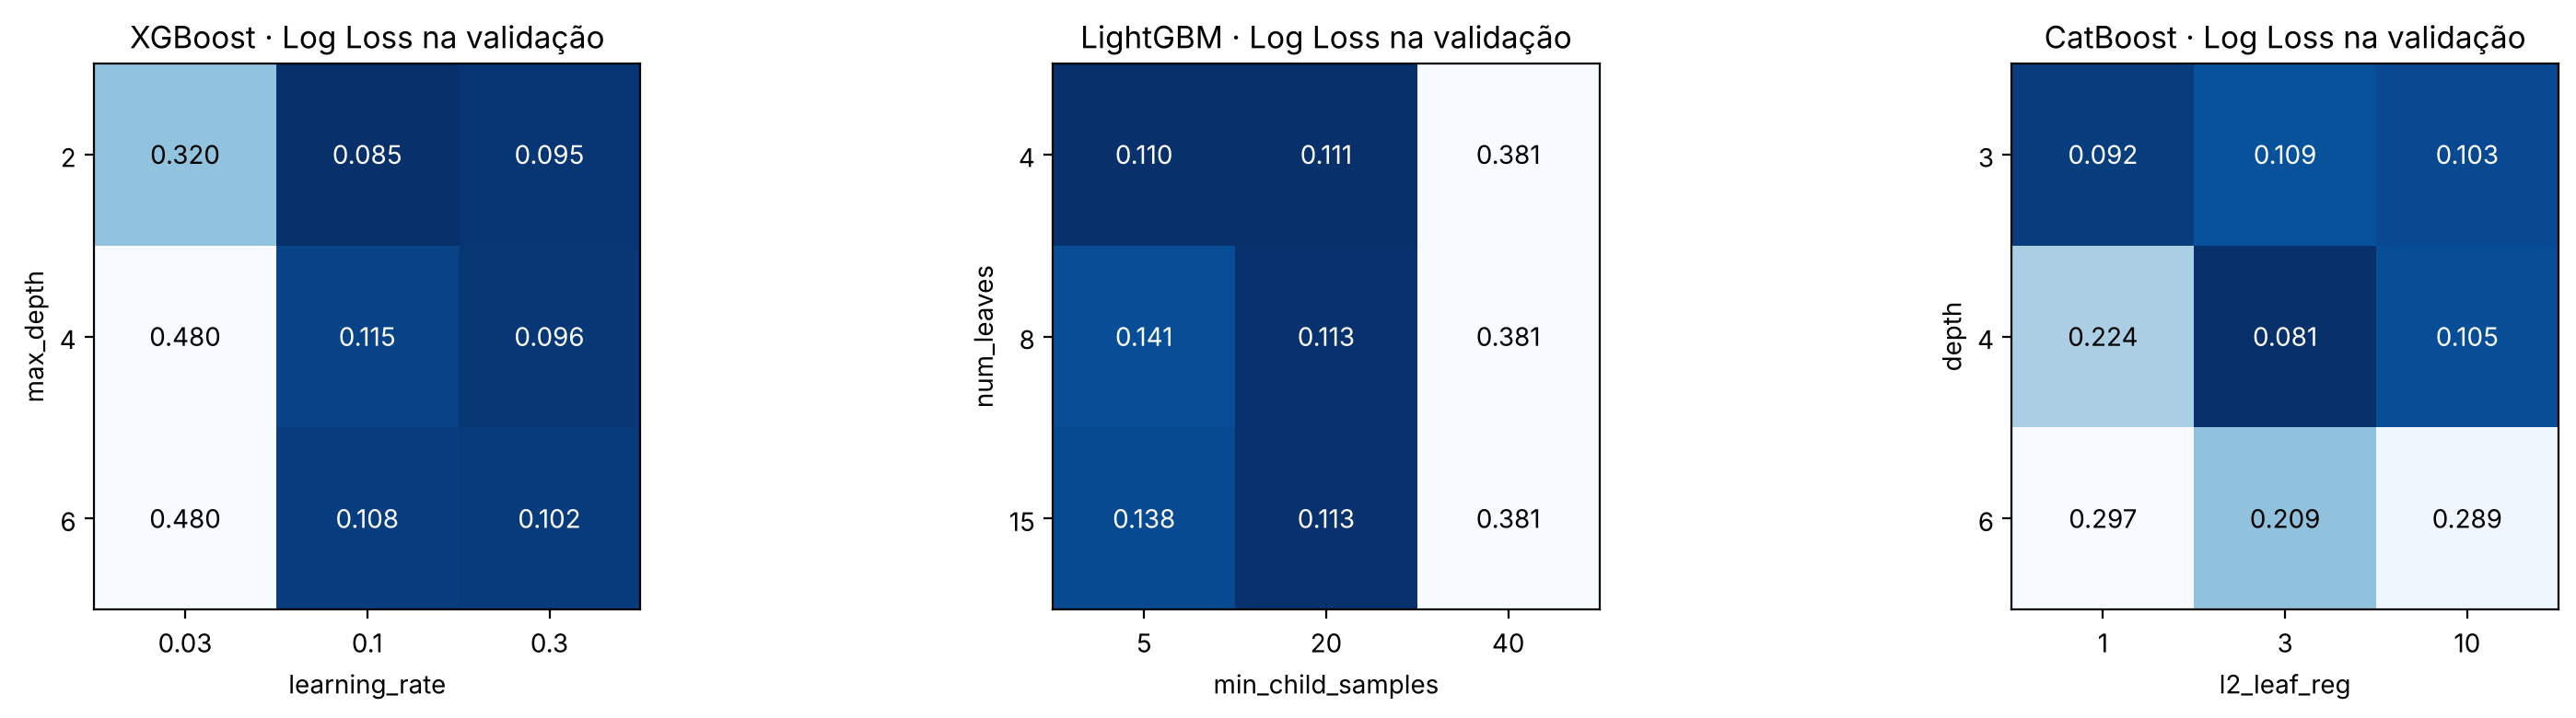

                                        param  AUC validação  Log Loss validação  árvores
Biblioteca                                                                               
CatBoost               depth=4, l2_leaf_reg=3         0.9957              0.0807      157
XGBoost        max_depth=4, learning_rate=0.3         0.9957              0.0961       90
LightGBM    num_leaves=4, min_child_samples=5         0.9928              0.1100      140

                   Acurácia  Precisão  Recall      F1  ROC AUC  Log Loss  Árvores  Tempo (s)
Modelo                                                                                      
XGBoost              0.9737       1.0  0.9286  0.9630   0.9947    0.0803      148     0.1198
LightGBM             0.9737       1.0  0.9286  0.9630   0.9954    0.0847      111     0.0284
CatBoost             0.9737       1.0  0.9286  0.9630   0.9950    0.0860      157     0.2616
XGBoost ajustado     0.9825       1.0  0.9524  0.9756   0.9897    0.0986       90   

In [10]:
grades = {
    "XGBoost": (treinar_xgb, "max_depth", [2, 4, 6], "learning_rate", [0.03, 0.1, 0.3]),
    "LightGBM": (treinar_lgbm, "num_leaves", [4, 8, 15], "min_child_samples", [5, 20, 40]),
    "CatBoost": (treinar_cat, "depth", [3, 4, 6], "l2_leaf_reg", [1, 3, 10]),
}
busca = []
for nome, (func, p1, v1, p2, v2) in grades.items():
    for a in v1:
        for b in v2:
            m, t, n = func(**{p1: a, p2: b})
            busca.append({"Biblioteca": nome, p1: a, p2: b, "param": f"{p1}={a}, {p2}={b}",
                          "AUC validação": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]),
                          "Log Loss validação": log_loss(y_val, m.predict_proba(X_val)[:, 1]),
                          "árvores": n, "tempo (s)": t, "modelo": m})
busca = pd.DataFrame(busca)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (nome, (func, p1, v1, p2, v2)) in zip(axes, grades.items()):
    t = busca[busca["Biblioteca"] == nome].pivot(index=p1, columns=p2, values="Log Loss validação")
    im = ax.imshow(t.values, cmap="Blues_r")
    ax.set_xticks(range(len(v2))); ax.set_xticklabels(v2); ax.set_xlabel(p2)
    ax.set_yticks(range(len(v1))); ax.set_yticklabels(v1); ax.set_ylabel(p1)
    for i in range(len(v1)):
        for j in range(len(v2)):
            v = t.values[i, j]
            cor = "white" if v < t.values.mean() else "black"
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", color=cor)
    ax.set_title(f"{nome} · Log Loss na validação")
plt.tight_layout(); plt.show()

# critério: maior AUC na validação; empate → menor Log Loss
escolhidos = (busca.sort_values(["AUC validação", "Log Loss validação"], ascending=[False, True])
                   .groupby("Biblioteca", sort=False).head(1).set_index("Biblioteca"))
print(escolhidos[["param", "AUC validação", "Log Loss validação", "árvores"]].round(4).to_string())

# só agora: os modelos escolhidos vão para o teste, uma única vez
ajustados = pd.DataFrame([metricas(f"{nome} ajustado", escolhidos.loc[nome, "modelo"],
                                   escolhidos.loc[nome, "tempo (s)"], escolhidos.loc[nome, "árvores"])
                          for nome in modelos]).set_index("Modelo")
print()
print(pd.concat([tabela.loc[list(modelos)], ajustados]).round(4).to_string())

## 14 · Conclusão técnica

**1. Os três boostings empataram no teste.** XGBoost, LightGBM e CatBoost acertaram **111 de 114** casos (97,4%). Os três têm a mesma matriz: **nenhum falso alarme** (precisão = 1,00) e **3 tumores malignos não detectados** (recall = 92,9%). Todos ficam muito acima do baseline, que sempre responde "benigno" e acerta 63,2% (AUC = 0,5).

| Critério | Vencedor | Valor | Observação |
|---|---|---|---|
| Melhor ROC AUC | LightGBM | 0,9954 | CatBoost 0,9950 · XGBoost 0,9947 |
| Melhor F1 | empate | 0,963 | mesmas previsões no limiar 0,5 |
| Menor Log Loss | XGBoost | 0,0803 | LightGBM 0,0847 · CatBoost 0,0860 |
| Menor tempo | LightGBM | ≈ 0,03 s | XGBoost ≈ 0,1 s · CatBoost ≈ 0,27 s |
| Menor gap treino − validação | CatBoost | 0,0043 | XGBoost 0,0085 · LightGBM 0,0071 |

As diferenças de AUC estão na **terceira casa decimal**. Com 114 amostras no teste, cada amostra vale 0,88 p.p. de acurácia, então **não dá para apontar um vencedor**: o resultado é um empate técnico.

**2. Boosting × Random Forest.** A floresta de 500 árvores (referência da aula 7.3) teve 95,6% de acurácia, com 1 falso alarme e 4 malignos perdidos. Ela até teve a maior AUC (0,9957), mas o **pior Log Loss (0,113)**: ordena bem os casos, porém as probabilidades são menos confiáveis. Também foi a mais lenta (≈ 0,6 s).

**3. Early stopping.** Nenhum modelo precisou das 800 árvores: o XGBoost parou em 148, o LightGBM em 111 e o CatBoost em 157. As curvas de validação sobem rápido nas primeiras ~50 árvores e depois ficam quase planas. Continuar treinando só aumentaria o risco de sobreajuste.

**4. Tempo.** O LightGBM foi o mais rápido (≈ 0,03 s), umas 3 vezes mais rápido que o XGBoost e perto de 10 vezes mais rápido que o CatBoost. Num dataset tão pequeno, todos levam menos de um segundo. Esses tempos valem só para esta máquina e esta execução.

**5. Importâncias.** Pela permutação na validação, `worst texture` foi a variável mais importante nos três modelos, seguida de medidas de tamanho e concavidade (`worst radius`, `area error`, `worst concave points`). A concordância entre os rankings ficou em **0,81 a 0,85** (Spearman), mais baixa que no exercício guiado (0,95 a 0,98). O motivo é a correlação: há 21 pares de variáveis com correlação acima de 0,9, e cada biblioteca escolhe uma "representante" diferente do mesmo grupo (raio, perímetro, área).

**6. Dois hiperparâmetros por biblioteca (etapa 13).**
- **CatBoost:** a melhor combinação na validação foi a própria configuração inicial (`depth=4`, `l2_leaf_reg=3`). Árvores com `depth=6` pioraram bastante o Log Loss (0,21 a 0,30): árvores profundas demais para só 341 amostras de treino.
- **XGBoost:** escolheu `max_depth=4` e `learning_rate=0.3`, com 90 árvores. No teste, acertou **1 maligno a mais** (98,2%, recall de 95,2%), mas a AUC caiu (0,9947 → 0,9897) e o Log Loss piorou (0,080 → 0,099). Um acerto a mais em 114 está dentro do ruído; as métricas de probabilidade mostram que **não foi uma melhora real**.
- **LightGBM:** escolheu `num_leaves=4` e `min_child_samples=5`. A acurácia ficou igual e o Log Loss melhorou um pouco (0,085 → 0,081). Com `min_child_samples=40`, o modelo parou com só 3 árvores (Log Loss de 0,381): folhas com tanta amostra mínima quase não conseguem dividir um treino tão pequeno.
- **Lição da grade:** com `learning_rate=0.03`, o Log Loss chegou a 0,48. O early stopping monitorava a **AUC**, que só mede a ordenação e estabilizou com 10 a 29 árvores. Nesse ponto, as probabilidades ainda estavam perto de 0,5. Com taxa de aprendizado pequena, convém monitorar o **Log Loss** ou dar mais paciência ao early stopping.

**Conclusão técnica:** neste problema, as três bibliotecas entregam o mesmo desempenho prático (97,4% de acurácia, nenhum falso alarme, 3 malignos perdidos) e superam a Random Forest em acurácia e em qualidade das probabilidades. A escolha fica pelos critérios secundários: o **LightGBM** foi o mais rápido, o **XGBoost** teve as probabilidades mais bem calibradas e o **CatBoost** teve o menor gap treino × validação. Como o limiar é 0,5 e o erro que importa é deixar passar um tumor maligno, o próximo passo seria **baixar o limiar** para priorizar o recall, escolhendo o novo limiar na validação.

**Limitações:** é um dataset pequeno (114 amostras no teste), com um único split e uma semente. A validação foi usada tanto para o early stopping quanto para escolher os hiperparâmetros, o que deixa as métricas de validação um pouco otimistas. Os hiperparâmetros das três bibliotecas não são equivalentes entre si, e os tempos são de uma única execução nesta máquina.